# 04. Dynamic Pricing Engine: Optimization and Historical Backtesting

`Forecast (Q0) → promotion-identified elasticity (E) → constrained optimization per product × store segment → gradual weekly price path → backtest`

**What makes it dynamic.** Every week the engine (1) re-forecasts baseline demand with XGBoost, (2) uses elasticities that are
**re-estimated every quarter** on all data available so far, (3) computes a **profit-optimal target price per product and store segment**
(value / mainstream / upscale), and (4) moves the shelf price toward that target by **at most 5% per week**. Prices therefore differ by store
type and change over time as new data arrives.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
from src import config
R = config.RESULTS_DIR
%matplotlib inline

In [2]:
from src import optimization as opt, backtesting as bt, elasticity as el, visualization as viz
import json
metrics = json.loads((R / "metrics.json").read_text())
rec = pd.read_csv(R / "recommendations_full.csv")
sel = pd.read_csv(R / "decision_elasticity.csv")
segd = pd.read_csv(R / "segment_elasticity.csv")

## 1. Demand-response function

$$Q_{s}(P) = Q_{0,s}\left(\frac{P}{P_{0,s}}\right)^{E_{s}}$$

| symbol | meaning | where it comes from |
|---|---|---|
| $s$ | product × store segment | value / mainstream / upscale stores |
| $P_{0,s}$ | current regular price | demand-weighted average of each store's last regular price in the segment |
| $Q_{0,s}$ | baseline weekly units at $P_{0,s}$, no promotion | **XGBoost** forecast for next week (bias-corrected), summed over the segment's stores |
| $E_{s}$ | price elasticity | promotion-identified M8 + shrinkage + segment adjustment (notebook 03) |

The forecast is made *at* $P_{0,s}$ with promotions off, and the elasticity describes relative changes around that point, so $P = P_{0,s}$
returns exactly the forecast.

## 2. Objective and constraints
* Profit $\Pi(P) = (P - C)\,Q(P)$ with **ASSUMED** $C = 0.7 \times$ the product's chain-level current price (30% gross margin; no cost in the data).
  The cost is the same for every store segment.
* Price band $0.8P_0 \le P \le 1.2P_0$; volume guardrail $Q(P) \ge 0.9\,Q_0$; cost floor $P > C$.
* **Dynamic rule:** the shelf price moves toward the target by at most 5% per week.
* If the cost floor lies above the allowed band (e.g. clearance pricing), the engine charges the highest allowed price and flags it.

Closed forms used as sanity checks: revenue ∝ $P^{1+E}$ (always a corner solution); profit optimum $P^* = C\,E/(1+E)$ for $E<-1$ (Lerner condition: margin $= -1/E$).

## 3. One product, step by step

In [3]:
r0 = rec.loc[(rec.elasticity - rec.elasticity.median()).abs().idxmin()]
Q0, P0, E, C = r0.demand_current, r0.current_price, r0.elasticity, r0.unit_cost_assumed
print(f"{r0['product']} | {r0.store_segment} stores: Q0={Q0:,.0f} units/week, P0=${P0:.2f}, E={E:.2f}, ASSUMED C=${C:.2f}")
for P in [0.8 * P0, P0, 1.1 * P0, 1.2 * P0]:
    q = opt.demand_at_price(P, Q0, P0, E)
    print(f"P=${P:.2f}  Q={q:8,.0f}  revenue=${P*q:9,.0f}  profit=${(P-C)*q:9,.0f}")
res_free = opt.optimize_price(Q0, P0, E, unit_cost=C, max_volume_loss=None)
res = opt.optimize_price(Q0, P0, E, unit_cost=C)
print("no volume guardrail :", round(res_free["recommended_price"], 3), res_free["binding_constraint"])
print("with volume guardrail:", round(res["recommended_price"], 3), res["binding_constraint"])
m = res["recommended_price"] / P0
print("weekly path (x current price):", np.round(opt.price_path(m, weeks=6), 3), "| weeks to target:", opt.weeks_to_target(m))
opt.sanity_checks(res)

RLDGLD PRETZEL STICKS 16 OZ | MAINSTREAM stores: Q0=281 units/week, P0=$3.29, E=-0.80, ASSUMED C=$2.30
P=$2.63  Q=     336  revenue=$      883  profit=$      110
P=$3.29  Q=     281  revenue=$      924  profit=$      277
P=$3.62  Q=     260  revenue=$      942  profit=$      343
P=$3.95  Q=     243  revenue=$      959  profit=$      399
no volume guardrail : 3.945 +price band
with volume guardrail: 3.753 volume guardrail
weekly path (x current price): [1.05  1.102 1.141 1.141 1.141 1.141] | weeks to target: 3


{'elasticity_negative': np.True_,
 'demand_decreasing_in_price': True,
 'optimizer_matches_grid': np.True_,
 'within_constraints': np.True_,
 'above_unit_cost': np.True_,
 'matches_closed_form': np.True_,
 'all_passed': True}

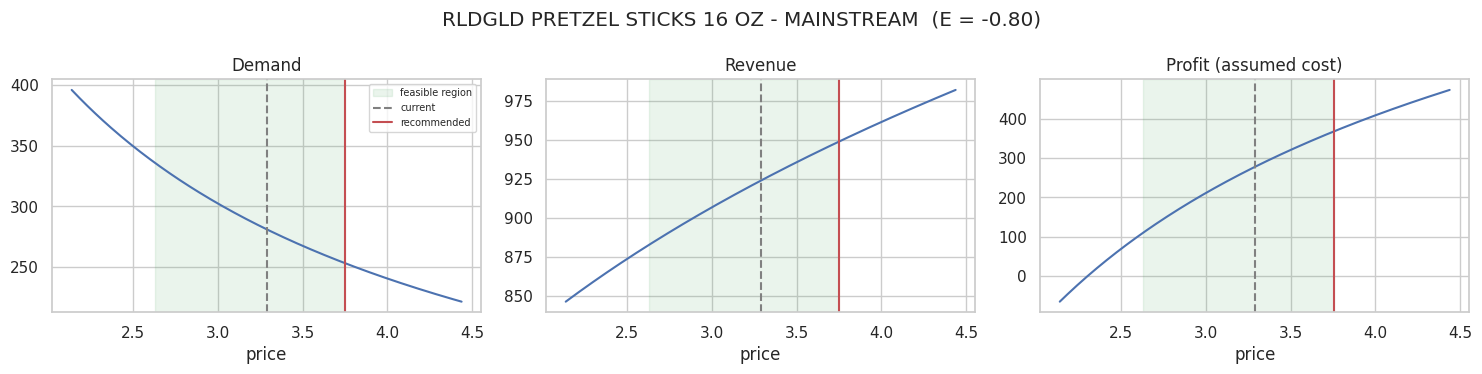

In [4]:
viz.objective_curves(res, title=f"{r0['product']} - {r0.store_segment}", name=None); plt.show()

## 4. The Lerner-condition problem (why the volume guardrail exists)

In [5]:
usable = sel.dropna(subset=["elasticity"])
print("usable products:", len(usable), "| with |E| <= 1 (profit rises with price, no finite optimum):", int((usable.elasticity >= -1).sum()))
lern = usable[usable.elasticity < -1]
print("implied optimal margin (-1/E) for elastic products, median:", round((-1 / lern.elasticity).median(), 2))
unconstrained = [opt.optimize_price(1, 1, e, unit_cost=0.7, max_volume_loss=None)["binding_constraint"] for e in usable.elasticity]
pd.Series(unconstrained).value_counts()

usable products: 51 | with |E| <= 1 (profit rises with price, no finite optimum): 32
implied optimal margin (-1/E) for elastic products, median: 0.67


+price band    51
Name: count, dtype: int64

With a 30% margin and these elasticities, a single-product profit model wants to raise almost every price to the band limit. That is
the Lerner condition at work: inelastic demand implies a much higher optimal margin than grocers actually run. A single-product model
omits store traffic and basket effects, competitor matching, long-run customer loss and price image. The **volume guardrail** (units may fall
at most 10%) stands in for these omitted effects. With it, less price-sensitive products are allowed bigger moves.

## 5. Next-week recommendations (product × store segment)
Products that are discontinued, being phased out, or have no usable price response are **not priced**:

In [6]:
pd.read_csv(R / "not_recommended_products.csv")

,upc,product,reason
0,3000006340,QKER LIFE ORIGINAL 13 OZ,being phased out: sold in ~7.0 stores/week ove...
1,3000006560,QKER CAP N CRUNCH BERRIES 13 OZ,being phased out: sold in ~2.0 stores/week ove...
2,3000006610,QKER CAP N CRUNCH 14 OZ,being phased out: sold in ~5.2 stores/week ove...
3,3500068914,COLG SPEARMINT WISP 16 CT,discontinued: no sales since 2011-03-30
4,7110410455,MKSL MINI TWIST PRETZELS 16 OZ,no usable price response: promotion-identified...
5,2840004768,RLDGLD TINY TWISTS PRTZL 16 OZ,no usable price response: promotion-identified...
6,1600027564,GM CHEERIOS 12 OZ,no usable price response: promotion-identified...
7,1111085345,PL RAISIN BRAN 20 OZ,no usable price response: promotion-identified...


In [7]:
biz = pd.read_csv(R / "business_recommendations.csv")
biz.head(15)

,product,category,store_segment,stores,current_price,target_price,target_change_pct,next_week_price,next_week_change_pct,weeks_to_target,elasticity,current_weekly_units,expected_weekly_units_at_target,current_weekly_revenue,expected_weekly_revenue_at_target,current_weekly_profit_ASSUMED_COST,expected_weekly_profit_at_target_ASSUMED_COST,binding_constraint
0,MKSL DUTCH PRETZELS 16 OZ,BAG SNACKS,MAINSTREAM,18.0000,2.0237,2.4284,0.2000,2.1249,0.0500,4,-0.4431,137.6066,126.9282,278.4740,308.2369,83.2830,128.1930,+price band
1,MKSL DUTCH PRETZELS 16 OZ,BAG SNACKS,UPSCALE,7.0000,2.0465,2.4557,0.2000,2.1488,0.0500,4,-0.4173,60.8659,56.4067,124.5593,138.5205,38.2228,58.5093,+price band
2,MKSL DUTCH PRETZELS 16 OZ,BAG SNACKS,VALUE,6.0000,2.0000,2.4000,0.2000,2.1000,0.0500,4,-0.1850,32.2563,31.1864,64.5127,74.8474,18.7580,30.6104,+price band
3,MKSL PRETZEL STICKS 16 OZ,BAG SNACKS,MAINSTREAM,20.0000,2.0300,2.4360,0.2000,2.1315,0.0500,4,-0.1293,135.7101,132.5489,275.4927,322.8905,83.8847,135.7458,+price band
4,MKSL PRETZEL STICKS 16 OZ,BAG SNACKS,UPSCALE,7.0000,2.0000,2.4000,0.2000,2.1000,0.0500,4,-0.1510,58.9579,57.3567,117.9158,137.6562,34.6737,56.6747,+price band
5,MKSL PRETZEL STICKS 16 OZ,BAG SNACKS,VALUE,7.0000,2.0000,2.4000,0.2000,2.1000,0.0500,4,-0.1222,45.0611,44.0685,90.1222,105.7644,26.5008,43.5445,+price band
6,PL MINI TWIST PRETZELS 15 OZ,BAG SNACKS,MAINSTREAM,43.0000,1.5304,1.7287,0.1296,1.6069,0.0500,3,-0.8647,"2,518.0979","2,266.2881","3,853.6986","3,917.7294","1,147.1741","1,481.8574",volume guardrail
7,PL MINI TWIST PRETZELS 15 OZ,BAG SNACKS,UPSCALE,15.0000,1.5525,1.7729,0.1420,1.6301,0.0500,3,-0.7934,"1,137.8196","1,024.0376","1,766.4249","1,815.5545",543.4635,714.8893,volume guardrail
8,PL MINI TWIST PRETZELS 15 OZ,BAG SNACKS,VALUE,19.0000,1.5211,1.7119,0.1254,1.5972,0.0500,3,-0.8918,458.7916,412.9124,697.8885,706.8707,204.7660,263.0605,volume guardrail
9,PL PRETZEL STICKS 15 OZ,BAG SNACKS,MAINSTREAM,43.0000,1.5145,1.7263,0.1399,1.5902,0.0500,3,-0.8048,"1,973.5079","1,776.1571","2,988.8178","3,066.2022",889.5929,"1,176.8998",volume guardrail


In [8]:
byp = pd.read_csv(R / "business_recommendations_by_product.csv")
print(rec.binding_constraint.value_counts())
checks = pd.read_csv(R / "optimization_sanity_checks.csv")
print("product x segment rows:", len(checks), "| all sanity checks passed:", bool(checks.all_passed.all()))
byp[["product", "current_price", "target_price", "target_change_pct", "elasticity_range", "current_weekly_units", "expected_weekly_units"]].round(3)

binding_constraint
volume guardrail    94
+price band         47
Name: count, dtype: int64
product x segment rows: 141 | all sanity checks passed: True


,product,current_price,target_price,target_change_pct,elasticity_range,current_weekly_units,expected_weekly_units
0,DIGIORNO THREE MEAT 29.8 OZ,5.6490,5.9370,0.0510,-2.14 to -2.07,737.7810,664.0030
1,NWMN OWN 4 CHEESE PIZZA 13.3 OZ,6.9820,7.3580,0.0540,-2.01 to -2.01,194.6410,175.1770
2,DIGRN SUPREME PIZZA 32.7 OZ,5.6580,5.9840,0.0580,-1.95 to -1.77,"1,001.7550",901.5800
3,KELL FROOT LOOPS 12.2 OZ,3.3070,3.4980,0.0580,-1.89 to -1.87,"1,807.4950","1,626.7450"
4,PL SR CRUST PEPPRN PIZZA 29.6 OZ,3.7600,3.9840,0.0600,-1.86 to -1.73,"1,127.2000","1,014.4800"
5,DIGRN PEPP PIZZA 28.3 OZ,5.6670,6.0510,0.0680,-1.66 to -1.49,"1,502.0790","1,351.8710"
6,POST FRUITY PEBBLES 11 OZ,2.8740,3.0770,0.0710,-1.62 to -1.47,"1,554.5280","1,399.0750"
7,LSTRNE FRS BRST ANTSPC MW 1 LT,4.9710,5.3370,0.0740,-1.69 to -1.44,346.5350,311.8820
8,PL SR CRUST SUPRM PIZZA 32.7 OZ,3.7010,3.9740,0.0740,-1.49 to -1.44,792.7340,713.4600
9,KELL BITE SIZE MINI WHEAT 18 OZ,3.6980,3.9850,0.0780,-1.44 to -1.35,"2,202.0150","1,981.8140"


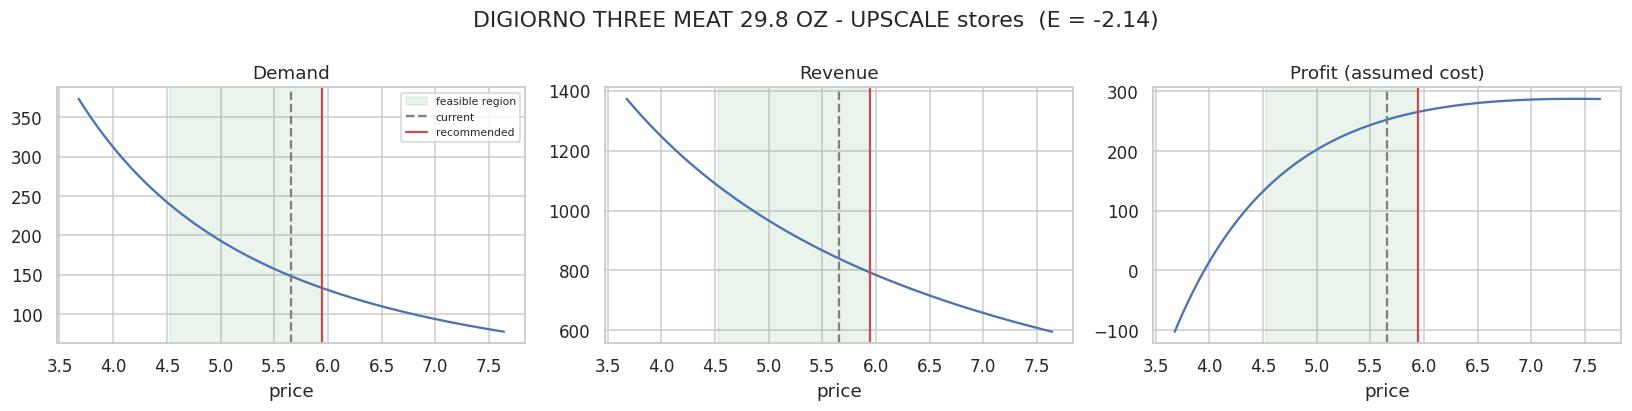

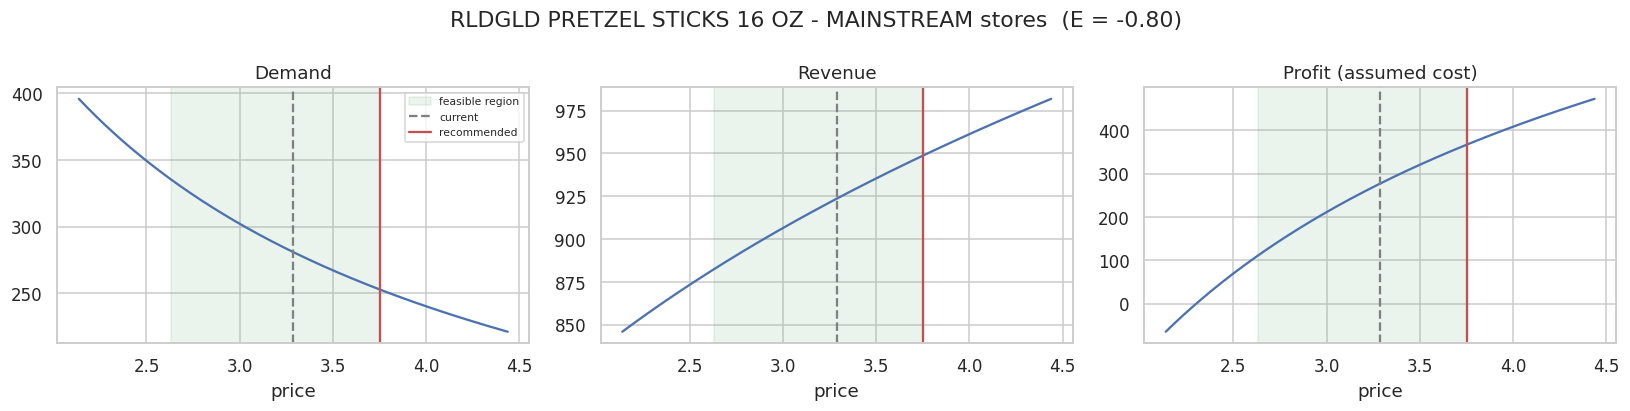

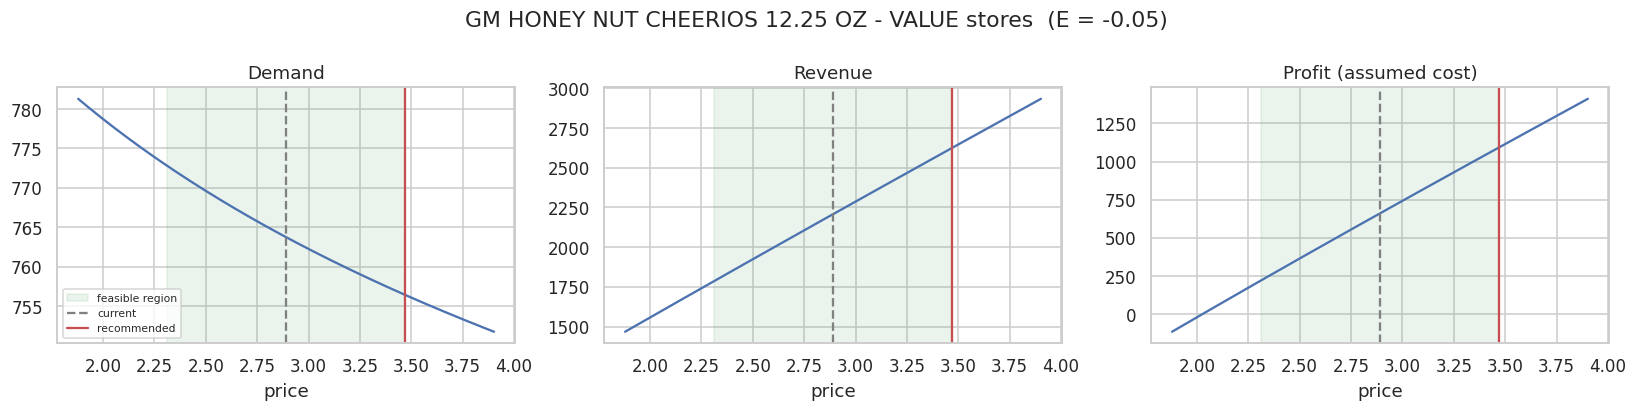

In [9]:
for tag in ["most_elastic", "median", "least_elastic"]:
    display(Image(filename=str(config.FIG_DIR / f"opt_curves_{tag}.png")))

### Why does the engine recommend this price? (human-readable)

In [10]:
for _, r in rec.sort_values("elasticity").iloc[[0, len(rec) // 2, -1]].iterrows():
    print(f"■ {r['product']} ({r.store_segment} stores): ${r.current_price:.2f} → target ${r.recommended_price:.2f} "
          f"({r.price_change_pct:+.1%}); next week ${r.next_week_price:.2f}, target reached in {r.weeks_to_target} week(s)")
    print("  ", r.explanation, "\n")

■ DIGIORNO THREE MEAT 29.8 OZ (UPSCALE stores): $5.66 → target $5.94 (+5.0%); next week $5.94, target reached in 2 week(s)
   Estimated price elasticity is -2.14: demand is elastic (|E| > 1). A 1% price rise is associated with a 2.14% drop in units. At the ASSUMED 30% margin, a higher price would raise expected profit, but the increase is capped where expected units fall by 10% (volume guardrail). The less elastic the product, the larger the price move the guardrail allows. Expected weekly units change -10.0%, price +5.0%. 

■ RLDGLD PRETZEL STICKS 16 OZ (UPSCALE stores): $3.29 → target $3.75 (+14.1%); next week $3.45, target reached in 3 week(s)
   Estimated price elasticity is -0.80: demand is inelastic (|E| < 1). A 1% price rise is associated with a 0.80% drop in units. At the ASSUMED 30% margin, a higher price would raise expected profit, but the increase is capped where expected units fall by 10% (volume guardrail). The less elastic the product, the larger the price move the guard

## 6. Sanity check: can XGBoost's own price response replace the elasticity?

In [11]:
xr = pd.read_csv(R / "xgb_price_response_diagnostic.csv")
print("share of products where XGBoost demand is monotone decreasing in price:", round(xr.xgb_monotone_decreasing.mean(), 2))
xr[["product", "elasticity", "xgb_arc_elasticity_0.8_to_1.2", "xgb_monotone_decreasing"]].sort_values("elasticity").round(2)

share of products where XGBoost demand is monotone decreasing in price: 0.43


,product,elasticity,xgb_arc_elasticity_0.8_to_1.2,xgb_monotone_decreasing
26,DIGIORNO THREE MEAT 29.8 OZ,-2.1300,-1.5600,True
33,NWMN OWN 4 CHEESE PIZZA 13.3 OZ,-2.0100,-1.4300,True
27,DIGRN SUPREME PIZZA 32.7 OZ,-1.9500,-1.3800,True
13,KELL FROOT LOOPS 12.2 OZ,-1.8700,-1.1600,True
31,PL SR CRUST PEPPRN PIZZA 29.6 OZ,-1.8600,-1.6100,True
28,DIGRN PEPP PIZZA 28.3 OZ,-1.6600,-1.2500,True
14,POST FRUITY PEBBLES 11 OZ,-1.5200,-1.2100,True
30,PL SR CRUST SUPRM PIZZA 32.7 OZ,-1.4900,-1.7400,True
41,LSTRNE FRS BRST ANTSPC MW 1 LT,-1.4400,-1.3200,False
18,KELL BITE SIZE MINI WHEAT 18 OZ,-1.4400,-0.6700,True


The tree model's price response is often flat or non-monotone. Trees learn price mostly from promotion weeks and cannot extrapolate,
so the engine uses XGBoost for the **level** of demand and the elasticity for the **slope**.

---
# Historical backtesting
Everything below is estimated on **2009-2010 only** and evaluated on **2011**, which was never used to fit anything.

## 7. Backtest 1: does the price response predict real held-out outcomes?
For **17,842 store-weeks in 2011** where a store cut the price *without* ad or display:
* **observed lift** = log units − average log units in that store-product's previous non-promoted weeks;
* **predicted lift** = elasticity × change in log price;
* *within-week* versions subtract the same quantities for stores that did **not** promote that product that week, which removes holidays,
  weather and other chain-wide shocks.

This is a real out-of-sample test: predictions from 2009-10 against outcomes that actually happened in 2011.

In [12]:
val = pd.read_csv(R / "price_response_validation.csv")
val.round(3)

,model,MAE_within_week,MAE_skill_within_week,calibration_slope,MAE_simple,MAE_skill_simple,n_events
0,No price effect (E = 0),0.4830,0.0000,NaN,0.5060,0.0000,17842
1,M1 naive OLS,0.4750,0.0170,0.3880,0.4680,0.0760,17842
2,M4 controlled OLS (store + week FE),0.4460,0.0780,0.8490,0.4540,0.1040,17842
3,M5 regular-price OLS,0.4470,0.0740,0.7540,0.4580,0.0950,17842
4,M7 promotion-calendar IV,0.5890,-0.2180,0.0850,0.5810,-0.1480,17842
5,M8 promotion-identified (raw),0.4560,0.0570,0.6500,0.4620,0.0870,17842
6,M8 + shrinkage (product level),0.4550,0.0590,1.0210,0.4620,0.0870,17842
7,M8 + shrinkage + store segment (ENGINE),0.4540,0.0600,1.0330,0.4620,0.0870,17842


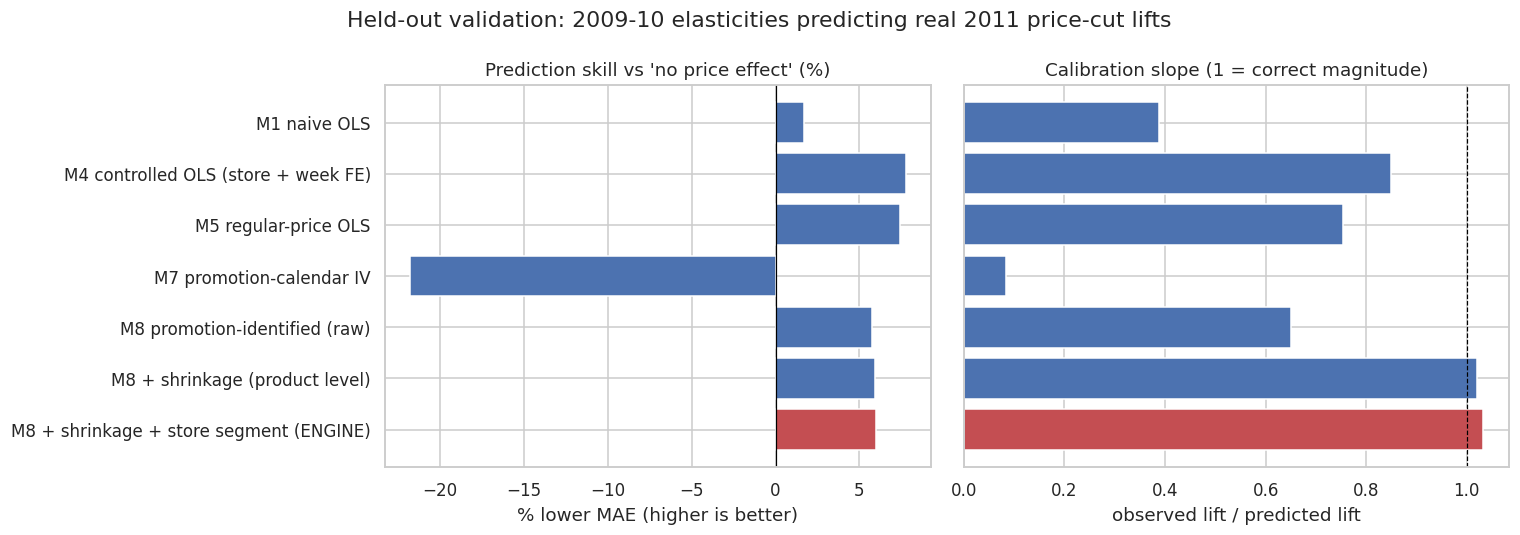

In [13]:
Image(filename=str(config.FIG_DIR / "bt_price_response_validation.png"))

**Reading the validation**
* **MAE skill** = how much the model reduces prediction error compared with assuming price has no effect. Every controlled model
  helps; the naive OLS barely does.
* **Calibration slope** = observed lift regressed on predicted lift. 1.0 means the *size* of the response is right, which is what pricing
  decisions depend on. The engine's elasticities are the best calibrated (≈ 1.0). Naive OLS overstates the response about 2.5×. The rejected IV is
  *worse than ignoring price*.
* Controlled OLS (M4) has slightly better MAE skill (7.8% vs 6.0%) but under-states magnitudes less well (slope 0.85).
* Absolute skill is modest because single store-weeks are noisy (weather, local events, stockouts). The point is that the elasticity used
  for decisions has the right sign and size on data it never saw.
* **Scope:** this validates the response to price **cuts** (the variation that exists). Price increases are an extrapolation.

## 8. Backtest 2: walk-forward simulation of the dynamic engine over 2011
Each quarter (2011-01-05, 04-06, 07-06, 10-05) the engine re-estimates elasticities on all data **before** that date, recomputes targets per
product × segment, and moves prices toward them at ≤ 5%/week. 2011 is then replayed with the retailer's actual promotion calendar, prices scaled
by the engine's multiplier and units adjusted by $m^{E}$.

**This part is a counterfactual simulation, not an observed outcome.** We never saw 2011 customers facing these prices. That is why the
same schedule is also judged under alternative elasticities.

,median_target,share_at_plus20,n
refit_week,,,
2011-01-05,1.1330,0.3030,165
2011-04-06,1.1270,0.2550,165
2011-07-06,1.1310,0.2780,162
2011-10-05,1.1240,0.2900,162
2012-01-04,1.1340,0.3020,162


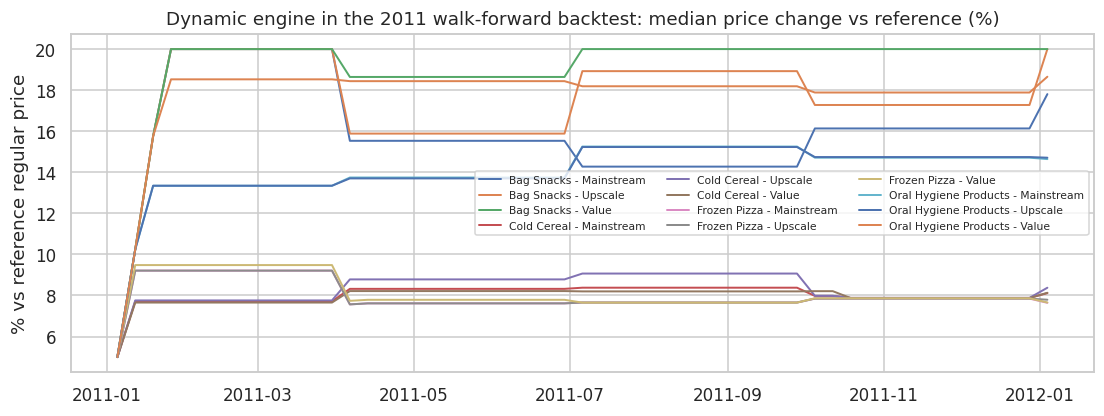

In [14]:
refits = pd.read_csv(R / "dynamic_refit_targets.csv")
display(refits.groupby("refit_week").agg(median_target=("target", "median"), share_at_plus20=("target", lambda s: (s > 1.199).mean()),
                                         n=("target", "size")).round(3))
Image(filename=str(config.FIG_DIR / "bt_dynamic_price_paths.png"))

In [15]:
bs = pd.read_csv(R / "backtest_summary.csv")
bs[["scenario", "revenue_change_pct", "profit_change_pct", "units_change_pct"]].round(4)

,scenario,revenue_change_pct,profit_change_pct,units_change_pct
0,Dynamic engine | judged by its own (quarterly ...,0.0178,0.3425,-0.0826
1,Dynamic engine | E re-estimated on 2011 data,0.0162,0.3438,-0.0723
2,Dynamic engine | E at less-elastic CI bound,0.0600,0.3960,-0.0515
3,Dynamic engine | E at more-elastic CI bound,-0.0276,0.2785,-0.1225
4,Dynamic engine | judged by controlled OLS (M4) E,-0.0204,0.2947,-0.1131
5,"Static policy (one price change, no segments)",0.0179,0.3501,-0.0853
6,Rule of thumb: +5% on everything,0.0006,0.1541,-0.0466
7,Naive-OLS policy | judged by engine E,0.0154,0.0758,-0.0088
8,Dynamic engine | assumed margin 20%,0.0178,0.7024,-0.0826
9,Dynamic engine | assumed margin 40%,0.0180,0.2084,-0.0822


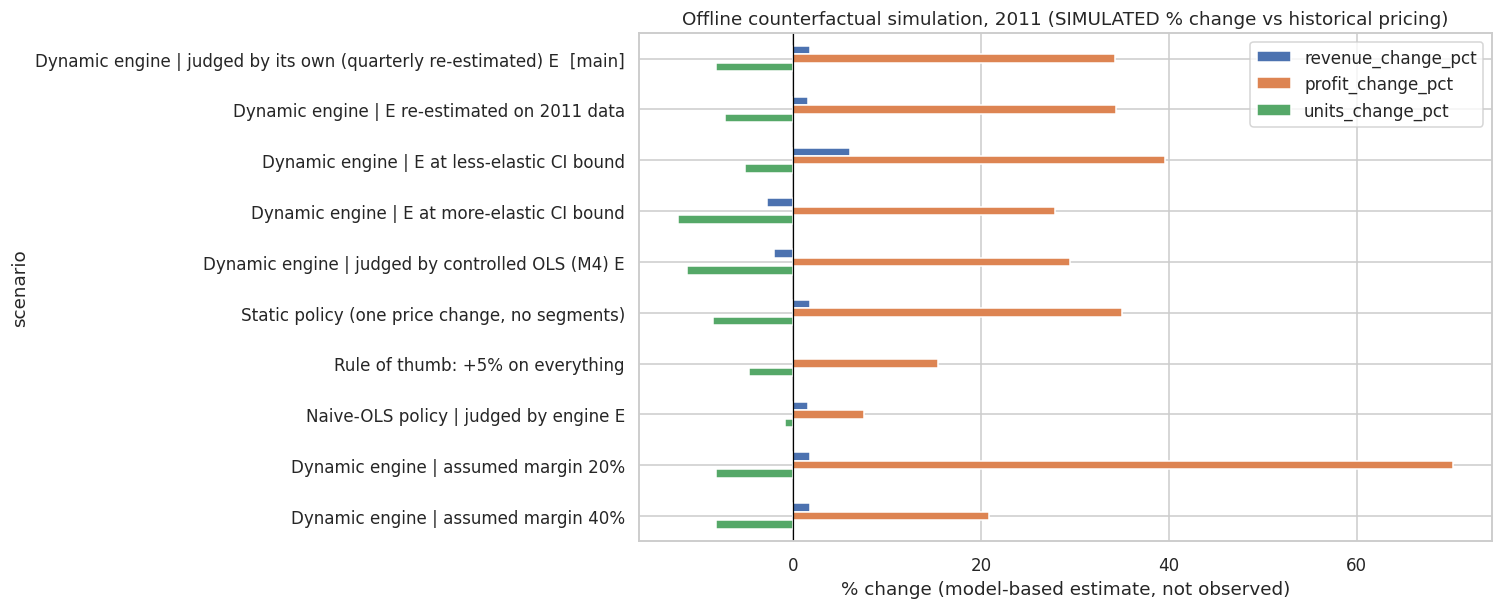

In [16]:
Image(filename=str(config.FIG_DIR / "bt_scenarios.png"))

In [17]:
bp = pd.read_csv(R / "backtest_by_product.csv")
bp[["description", "units_change_pct", "revenue_change_pct", "profit_change_pct", "profit_change_abs"]].sort_values("profit_change_abs").round(3)

,description,units_change_pct,revenue_change_pct,profit_change_pct,profit_change_abs
14,GM CHEERIOS,0.0000,0.0000,0.0000,0.0000
24,COLG SPEARMINT WISP,-0.0570,0.1180,NaN,173.3100
37,MKSL MINI TWIST PRETZELS,-0.0050,0.0290,0.1020,947.7340
17,NWMN OWN SUPREME PIZZA,-0.1000,-0.0350,0.1440,"2,292.2400"
33,ACT RSTR CL SPLSH MINT MW,-0.0980,0.0290,0.3640,"2,856.4720"
32,ACT KIDS BBLGUM FLUOR RNS,-0.0950,0.0570,0.4710,"3,337.3470"
51,LSTRNE FRS BRST ANTSPC MW,-0.1000,-0.0360,0.1860,"3,520.2660"
23,QKER CAP N CRUNCH,-0.1000,-0.0480,0.1160,"3,561.5290"
21,QKER LIFE ORIGINAL,-0.1000,-0.0560,NaN,"3,695.0500"
25,CREST PH WHTG CLN MINT TP,-0.0910,0.0290,1.1780,"3,710.0190"


**Reading the simulation**
* Under the model assumptions the dynamic engine raises (assumed-cost) profit by about a third: margin goes up, volume goes down by less than
  the guardrail (the gradual path delays part of the drop).
* **Stress tests:** judged by elasticities re-estimated on 2011, by either CI bound, or by a *different* model (controlled OLS), the simulated
  gain stays clearly positive. The schedule is not fragile to elasticity uncertainty *of the size we measured*.
* **Dynamic vs static:** a single immediate price change (static policy) gives a similar, slightly higher simulated profit. Moving at
  most 5% per week gives up a little profit in the first weeks, and the store-segment differences are small. The value of the dynamic engine is
  **control and adaptivity**: smaller weekly jumps, prices that update as elasticities are re-estimated, and store-type differentiation. It is
  not extra simulated profit in this data.
* **Margin:** the % gain depends heavily on the assumed cost (20% vs 40% margin). The price *schedule* barely changes, because constraints bind.
* A naive-OLS policy and a flat +5% rule capture much less of the gain.
* For clearance or phase-out products the historical assumed profit can be negative, so the table shows the absolute difference.

## 9. Counterfactual limitations: why the simulation is not a causal experiment
* We **do not observe** demand at the alternative prices; simulated units are an elasticity-adjusted version of observed units.
* Price **increases** are outside the validated range (validation covers price cuts).
* **Competitors**, promotion plans and customer habits would react; the simulation holds them fixed.
* **Inventory** limits and **cross-product** effects (cannibalisation, basket/traffic) are ignored.
* The **cost is assumed**.

### How a retailer should validate this for real
1. Randomly assign matched stores (stratified by segment and size) to test and control.
2. Run the engine in test stores for 8-12 weeks within the same guardrails.
3. Estimate the effect with difference-in-differences on units, margin, basket size and category sales.
4. Feed the experimental elasticities back into the engine as the best available estimates.